In [1]:
#Import necessary libraries
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn import preprocessing

In [2]:
 # Read the dataset
df = pd.read_csv("fifa_players.csv")

In [3]:
df.head()

,name,full_name,birth_date,age,height_cm,weight_kgs,positions,nationality,overall_rating,potential,...,long_shots,aggression,interceptions,positioning,vision,penalties,composure,marking,standing_tackle,sliding_tackle
0,L. Messi,Lionel Andrés Messi Cuccittini,6/24/1987,31,170.18,72.1,"CF,RW,ST",Argentina,94,94,...,94,48,22,94,94,75,96,33,28,26
1,C. Eriksen,Christian Dannemann Eriksen,2/14/1992,27,154.94,76.2,"CAM,RM,CM",Denmark,88,89,...,89,46,56,84,91,67,88,59,57,22
2,P. Pogba,Paul Pogba,3/15/1993,25,190.50,83.9,"CM,CAM",France,88,91,...,82,78,64,82,88,82,87,63,67,67
3,L. Insigne,Lorenzo Insigne,6/4/1991,27,162.56,59.0,"LW,ST",Italy,88,88,...,84,34,26,83,87,61,83,51,24,22
4,K. Koulibaly,Kalidou Koulibaly,6/20/1991,27,187.96,88.9,CB,Senegal,88,91,...,15,87,88,24,49,33,80,91,88,87


In [4]:
 #review columns
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17954 entries, 0 to 17953
Data columns (total 51 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   name                           17954 non-null  object 
 1   full_name                      17954 non-null  object 
 2   birth_date                     17954 non-null  object 
 3   age                            17954 non-null  int64  
 4   height_cm                      17954 non-null  float64
 5   weight_kgs                     17954 non-null  float64
 6   positions                      17954 non-null  object 
 7   nationality                    17954 non-null  object 
 8   overall_rating                 17954 non-null  int64  
 9   potential                      17954 non-null  int64  
 10  value_euro                     17699 non-null  float64
 11  wage_euro                      17708 non-null  float64
 12  preferred_foot                 17954 non-null 

In [5]:
 # get the dataset shape
df.shape

(17954, 51)

In [56]:
# get the number of missing values per column
df.isnull().sum()

name                      0
full_name                 0
birth_date                0
age                       0
height_cm                 0
weight_kgs                0
positions                 0
nationality               0
overall_rating            0
potential                 0
value_euro              255
wage_euro               246
preferred_foot            0
weak_foot(1-5)            0
skill_moves(1-5)          0
body_type                 0
release_clause_euro    1837
crossing                  0
finishing                 0
heading_accuracy          0
short_passing             0
volleys                   0
dribbling                 0
curve                     0
freekick_accuracy         0
long_passing              0
ball_control              0
acceleration              0
sprint_speed              0
agility                   0
reactions                 0
balance                   0
shot_power                0
jumping                   0
stamina                   0
strength            

In [7]:
# Percentage of missing values per column
(df.isnull().sum())*100/len(df)

name                              0.000000
full_name                         0.000000
birth_date                        0.000000
age                               0.000000
height_cm                         0.000000
weight_kgs                        0.000000
positions                         0.000000
nationality                       0.000000
overall_rating                    0.000000
potential                         0.000000
value_euro                        1.420296
wage_euro                         1.370168
preferred_foot                    0.000000
international_reputation(1-5)     0.000000
weak_foot(1-5)                    0.000000
skill_moves(1-5)                  0.000000
body_type                         0.000000
release_clause_euro              10.231703
national_team                    95.226690
national_rating                  95.226690
national_team_position           95.226690
national_jersey_number           95.226690
crossing                          0.000000
finishing  

In [8]:
 # remove some useless coulmns
df = df.drop(columns=[
    'national_team',
    'national_rating',
    'national_team_position',
    'national_jersey_number',
    'international_reputation(1-5)'
])

In [9]:
# Count the occurrences of each "body type"
df['body_type'].value_counts()

body_type
Normal                 10393
Lean                    6468
Stocky                  1086
Messi                      1
Courtois                   1
PLAYER_BODY_TYPE_25        1
Akinfenwa                  1
Shaqiri                    1
Neymar                     1
C. Ronaldo                 1
Name: count, dtype: int64

In [10]:
df.describe()

,age,height_cm,weight_kgs,overall_rating,potential,value_euro,wage_euro,weak_foot(1-5),skill_moves(1-5),release_clause_euro,...,long_shots,aggression,interceptions,positioning,vision,penalties,composure,marking,standing_tackle,sliding_tackle
count,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,1.769900e+04,17708.000000,17954.000000,17954.000000,1.611700e+04,...,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000
mean,25.565445,174.946921,75.301047,66.240169,71.430935,2.479280e+06,9902.134628,2.945695,2.361034,4.622522e+06,...,46.852456,55.816531,46.657959,49.857302,53.406260,48.357302,58.680183,47.162861,47.733040,45.705915
std,4.705708,14.029449,7.083684,6.963730,6.131339,5.687014e+06,21995.593750,0.663691,0.763223,1.129077e+07,...,19.429337,17.394047,20.754649,19.694311,14.156038,15.810844,11.625541,20.037346,21.674973,21.285812
min,17.000000,152.400000,49.900000,47.000000,48.000000,1.000000e+04,1000.000000,1.000000,1.000000,1.300000e+04,...,3.000000,11.000000,3.000000,2.000000,10.000000,5.000000,12.000000,3.000000,2.000000,3.000000
25%,22.000000,154.940000,69.900000,62.000000,67.000000,3.250000e+05,1000.000000,3.000000,2.000000,5.250000e+05,...,32.000000,44.000000,26.000000,38.000000,44.000000,38.000000,51.000000,30.000000,27.000000,24.000000
50%,25.000000,175.260000,74.800000,66.000000,71.000000,7.000000e+05,3000.000000,3.000000,2.000000,1.200000e+06,...,51.000000,59.000000,52.000000,55.000000,55.000000,49.000000,60.000000,52.500000,55.000000,52.000000
75%,29.000000,185.420000,79.800000,71.000000,75.000000,2.100000e+06,9000.000000,3.000000,3.000000,3.500000e+06,...,62.000000,69.000000,64.000000,64.000000,64.000000,60.000000,67.000000,64.000000,66.000000,64.000000
max,46.000000,205.740000,110.200000,94.000000,95.000000,1.105000e+08,565000.000000,5.000000,5.000000,2.265000e+08,...,94.000000,95.000000,92.000000,95.000000,94.000000,92.000000,96.000000,94.000000,93.000000,90.000000


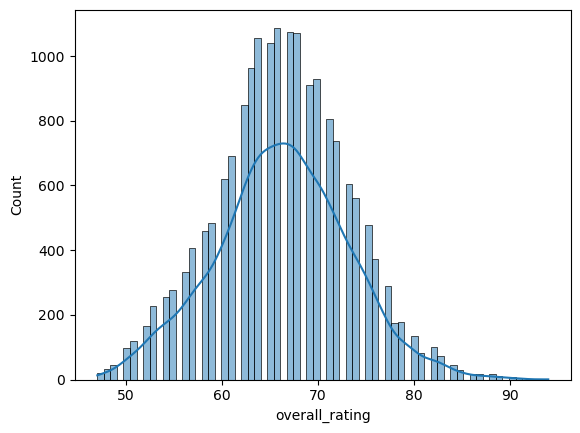

In [11]:
 # Plot the distribution of overall ratings
sns.histplot(df['overall_rating'], kde=True)
plt.show()

In [12]:
# Count the occurrences of each "positions"
df["positions"].value_counts()

positions
CB              2243
GK              2065
ST              1747
CM               764
CDM,CM           709
                ... 
LB,CM,LWB          1
CF,ST,LM,RM        1
CAM,CM,RW,LW       1
CF,LM,RM           1
CF,CAM,CM          1
Name: count, Length: 890, dtype: int64

In [13]:
# Count the occurrences of each "preferred foot"
df['preferred_foot'].value_counts()

preferred_foot
Right    13781
Left      4173
Name: count, dtype: int64

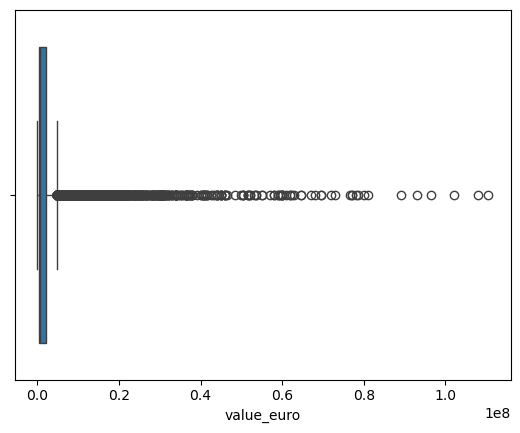

In [14]:
 # review the outliers for "value euro"
sns.boxplot(x=df['value_euro'])
plt.show()

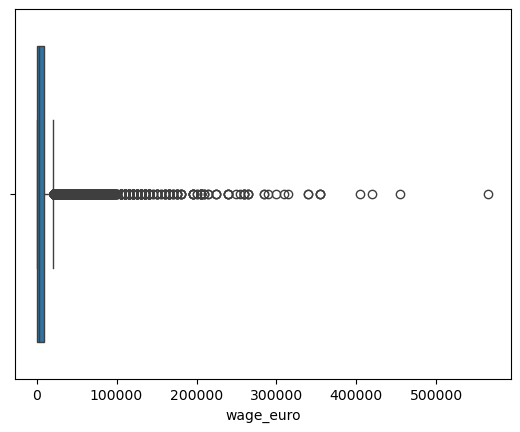

In [15]:
 # review the outliers for "wage euro"
sns.boxplot(x=df['wage_euro'])
plt.show()

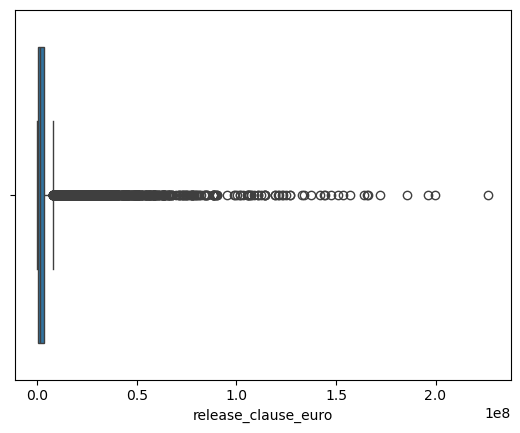

In [16]:
 # review the outliers for "release clause euro"
sns.boxplot(x=df['release_clause_euro'])
plt.show()

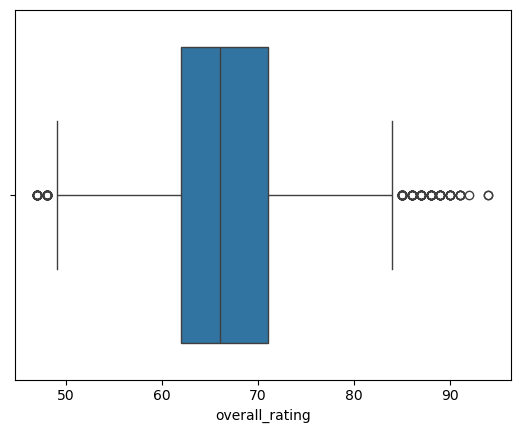

In [17]:
 # review the outliers for "overall rating"
sns.boxplot(x=df['overall_rating'])
plt.show()

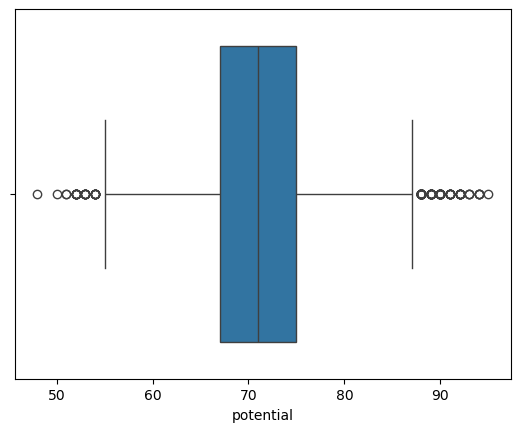

In [18]:
 # review the outliers for "potential"
sns.boxplot(x=df['potential'])
plt.show()

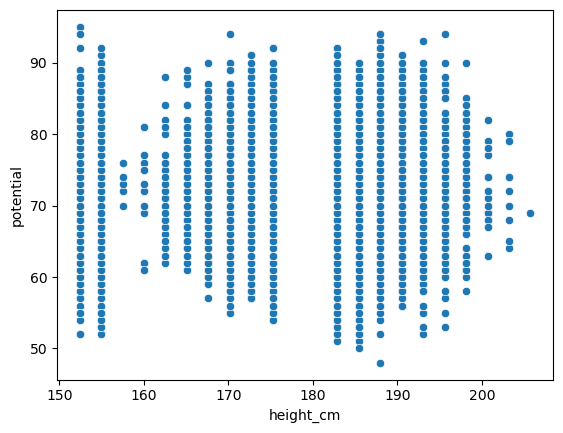

In [19]:
 # Plot the relationship between height and potential
sns.scatterplot(
    data=df,
    x="height_cm",
    y="potential"
)

plt.show()

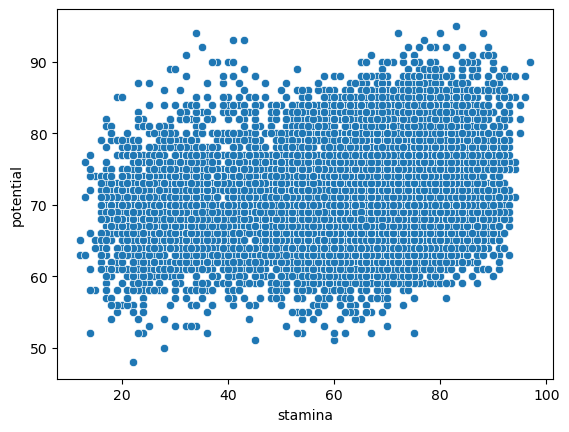

In [20]:
 # Plot the relationship between stamina and potential
sns.scatterplot(
    data=df,
    x="stamina",
    y="potential"
)

plt.show()

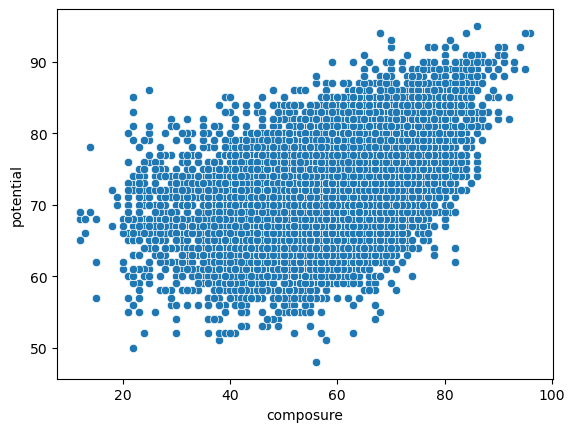

In [21]:
 # Plot the relationship between composure and potential
sns.scatterplot(
    data=df,
    x="composure",
    y="potential"
)

plt.show()

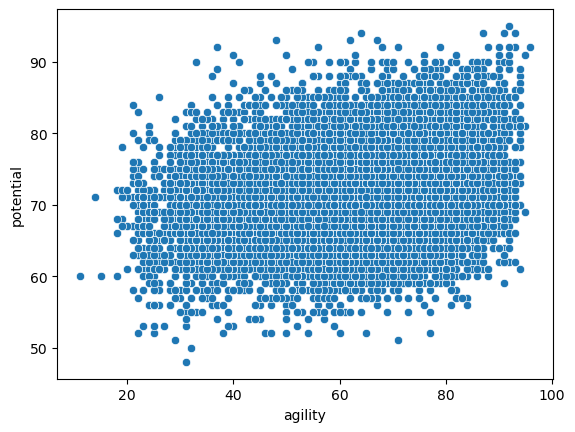

In [22]:
 # Plot the relationship between agility and potential
sns.scatterplot(
    data=df,
    x="agility",
    y="potential"
)

plt.show()

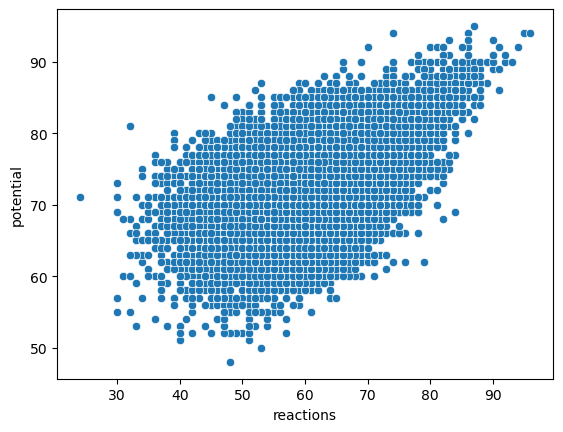

In [23]:
 # Plot the relationship between reactions and potential
sns.scatterplot(
    data=df,
    x="reactions",
    y="potential"
)

plt.show()

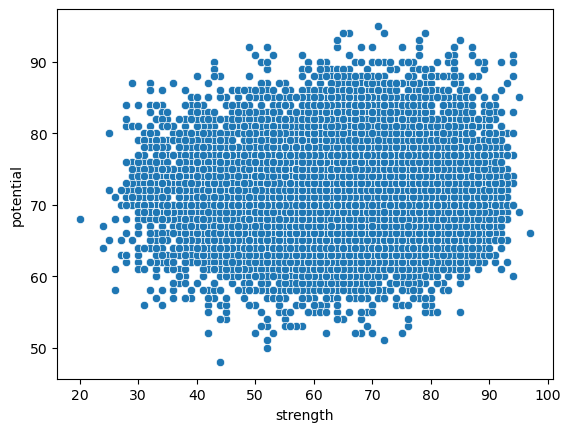

In [24]:
 # Plot the relationship between strength and potential
sns.scatterplot(
    data=df,
    x="strength",
    y="potential"
)

plt.show()

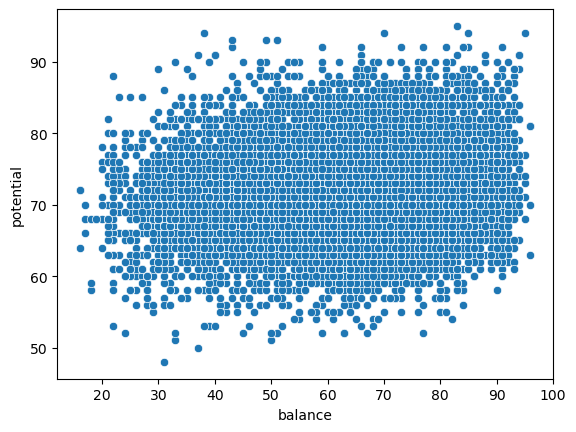

In [25]:
 # Plot the relationship between balance and potential
sns.scatterplot(
    data=df,
    x="balance",
    y="potential"
)

plt.show()

<Axes: >

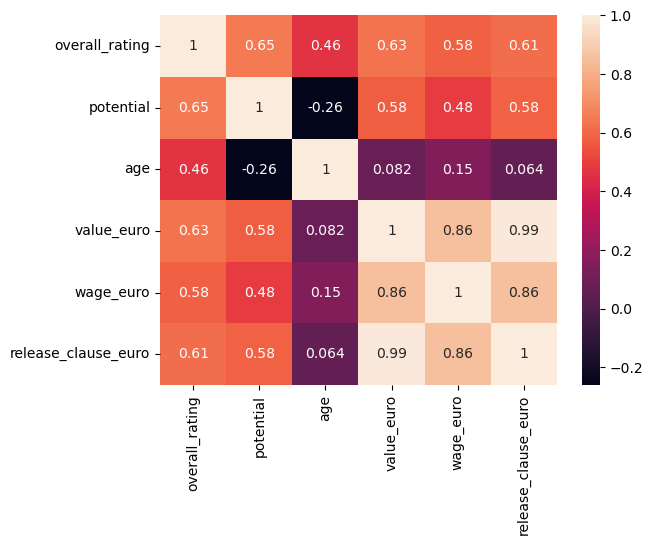

In [26]:
# Visualize the correlation matrix using a heatmap
cols = [
    'overall_rating',
    'potential',
    'age',
    'value_euro',
    'wage_euro',
    'release_clause_euro'
]

sns.heatmap(
    df[cols].corr(),
    annot=True
)

In [27]:
 # Categorize players based on their positions
def get_role(position):
    positions = position.split(',')

    if any(p.strip() in ['ST', 'CF','LW', 'RW'] for p in positions):
        return 'Forward'

    elif any(p.strip() in ['CM', 'CAM', 'CDM', 'LM', 'RM'] for p in positions):
        return 'Midfielder'

    elif any(p.strip() in ['CB', 'LB', 'RB', 'LWB', 'RWB'] for p in positions):
        return 'Defender'

    elif any(p.strip() == 'GK' for p in positions):
        return 'Goalkeeper'

    return 'Other'

In [28]:
 # Create a new column with player roles based on positions
df['role'] = df['positions'].apply(get_role)

In [29]:
# create a dataframe for each role
forward_df = df[df['role'] == 'Forward'].copy()

midfielder_df = df[df['role'] == 'Midfielder'].copy()

defender_df = df[df['role'] == 'Defender'].copy()

In [30]:
 # select features for forwards
forward_features = forward_df[[
'age',
'finishing',
'dribbling',
'ball_control',
'shot_power',
'positioning',
'long_shots',
'penalties',
'weak_foot(1-5)',
'skill_moves(1-5)',
'crossing',
'heading_accuracy',
'short_passing',
'vision',
'volleys',
'curve',
'freekick_accuracy',
'acceleration',
'sprint_speed',
'agility',
'reactions',
'balance',
'jumping',
'stamina',
'strength',
'composure'
]]

In [31]:
 #Split data into training and testing sets (80% train, 20% test)
from sklearn.model_selection import train_test_split

X = forward_features
y = forward_df['potential']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [32]:
 #Fit the random forest regressor model
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(random_state=42)
rf.fit(X_train,y_train)
 #Predict on test set
y_hat1 = rf.predict(X_test)

In [33]:
 #Evaluate model with MAE and MSE
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_hat1)
rmse = np.sqrt(mean_squared_error(y_test, y_hat1))
r2 = r2_score(y_test, y_hat1)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 1.5740945790080738
RMSE: 2.120157335677633
R²: 0.8814716631299969


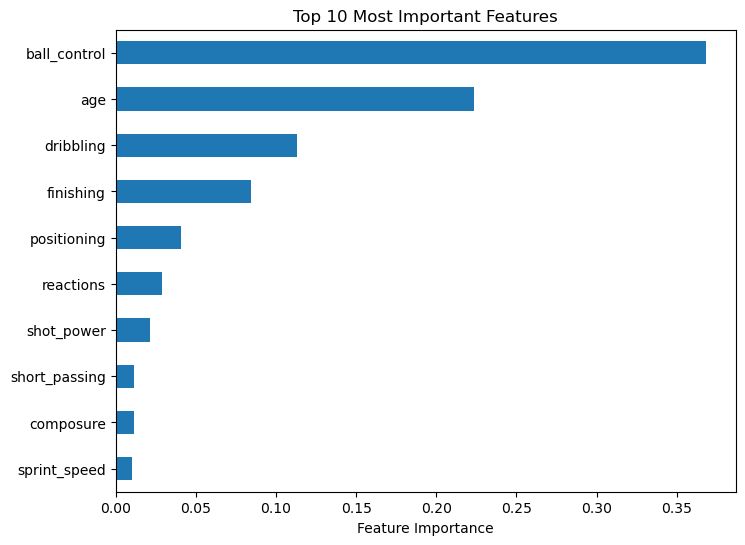

In [34]:
 # create a feature importance ranking
importance = pd.Series(
    rf.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

 # visualize the top 10 important features
plt.figure(figsize=(8,6))
importance.head(10).plot(kind='barh')
plt.xlabel("Feature Importance")
plt.title("Top 10 Most Important Features")
plt.gca().invert_yaxis()
plt.show()

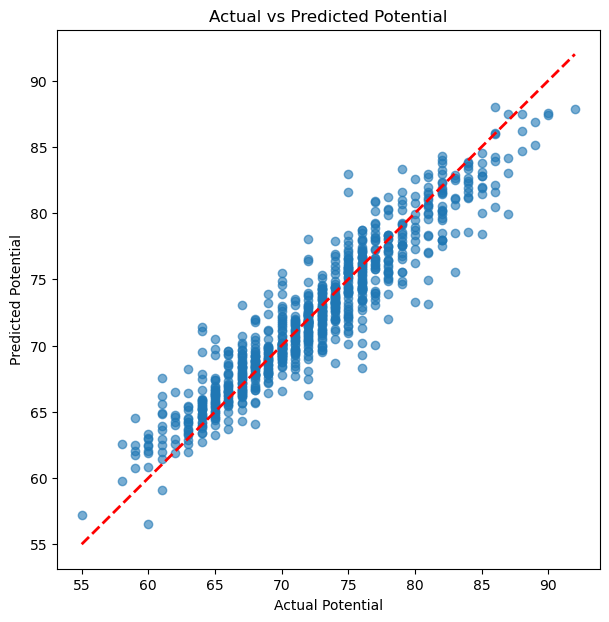

In [35]:
 #Plot Actual vs Predicted scatter
plt.figure(figsize=(7,7))
plt.scatter(y_test, y_hat1, alpha=0.6)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linestyle='--',
    linewidth=2
)

plt.xlabel("Actual Potential")
plt.ylabel("Predicted Potential")
plt.title("Actual vs Predicted Potential")

plt.show()

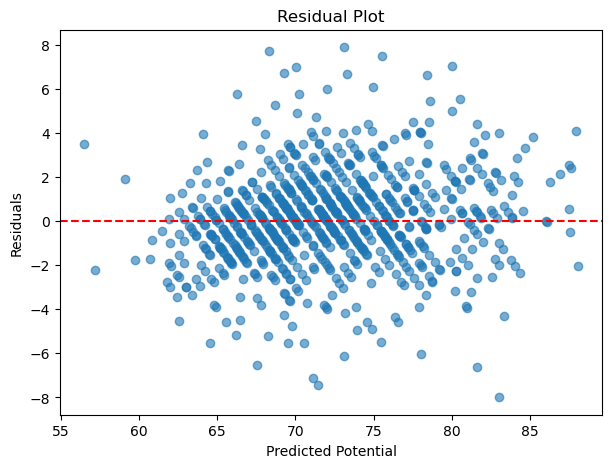

In [36]:
 #PLot residuals scatter
residuals = y_test - y_hat1

plt.figure(figsize=(7,5))
plt.scatter(y_hat1, residuals, alpha=0.6)

plt.axhline(
    y=0,
    color='red',
    linestyle='--'
)

plt.xlabel("Predicted Potential")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.show()

In [37]:
 # select features for midfielders
midfielder_features = midfielder_df[[  
    'age',
    'dribbling',
    'shot_power',
    'positioning',
    'weak_foot(1-5)',
    'skill_moves(1-5)',
    'crossing',
    'long_passing',
    'short_passing',
    'volleys',
    'curve',
    'freekick_accuracy',
    'reactions',
    'balance',
    'stamina',
    'strength',
    'composure',
    'acceleration',
    'aggression',
    'interceptions',
    'vision',
    'standing_tackle', 
    'ball_control',
    'long_shots'
]]

In [53]:
#Split data into training and testing sets (80% train, 20% test)

X = midfielder_features
y = midfielder_df['potential']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [54]:
 #Fit the random forest regressor model
rf = RandomForestRegressor(random_state=42)
rf.fit(X_train,y_train)
 #Predict on test set
y_hat2 = rf.predict(X_test)

In [55]:
 #Evaluate model with MAE and MSE
mae = mean_absolute_error(y_test, y_hat2)
rmse = np.sqrt(mean_squared_error(y_test, y_hat2))
r2 = r2_score(y_test, y_hat2)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 1.6626099925428783
RMSE: 2.194199627646878
R²: 0.8761497378312942


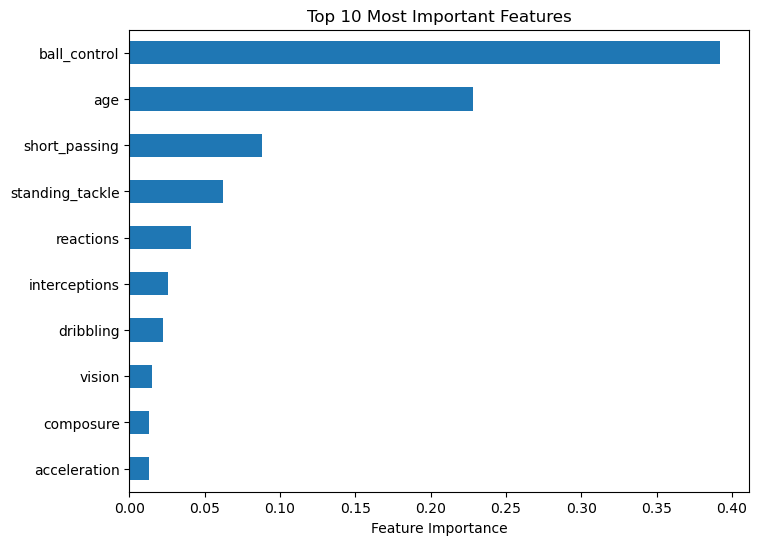

In [41]:
 # create a feature importance ranking
importance = pd.Series(
    rf.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

 # visualize the top 10 important features
plt.figure(figsize=(8,6))
importance.head(10).plot(kind='barh')
plt.xlabel("Feature Importance")
plt.title("Top 10 Most Important Features")
plt.gca().invert_yaxis()
plt.show()

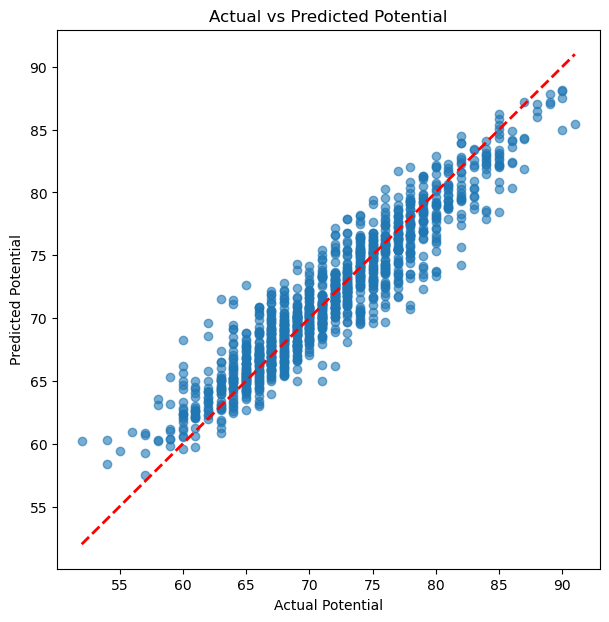

In [42]:
 #Plot Actual vs Predicted scatter
plt.figure(figsize=(7,7))
plt.scatter(y_test, y_hat2, alpha=0.6)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linestyle='--',
    linewidth=2
)

plt.xlabel("Actual Potential")
plt.ylabel("Predicted Potential")
plt.title("Actual vs Predicted Potential")

plt.show()

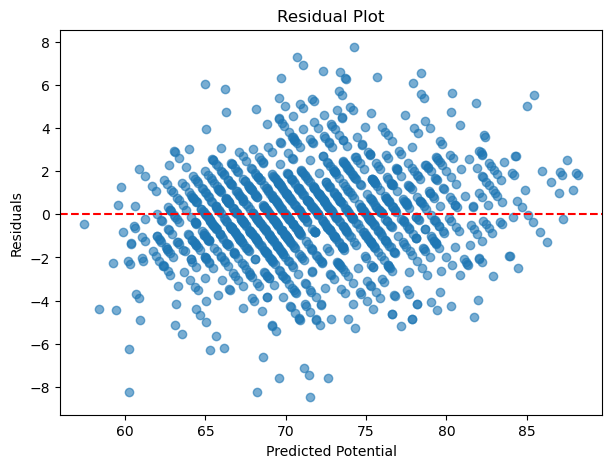

In [43]:
 #PLot residuals scatter
residuals = y_test - y_hat2

plt.figure(figsize=(7,5))
plt.scatter(y_hat2, residuals, alpha=0.6)

plt.axhline(
    y=0,
    color='red',
    linestyle='--'
)

plt.xlabel("Predicted Potential")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.show()

In [44]:
 # select features for defenders
defender_features = defender_df[[  
    'age',
    'height_cm',
    'weight_kgs',
    'positioning',
    'short_passing',
    'freekick_accuracy',
    'reactions',
    'balance',
    'stamina',
    'strength',
    'composure',
    'acceleration',
    'aggression',
    'interceptions',
    'standing_tackle', 
    'sliding_tackle',
    'heading_accuracy',
    'jumping',
    'marking',
]]

In [45]:
#Split data into training and testing sets (80% train, 20% test)
from sklearn.model_selection import train_test_split

X = defender_features
y = defender_df['potential']

X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,
    test_size=0.2,
    random_state=42
    
)

In [52]:
 #Fit the random forest regressor model
rf = RandomForestRegressor(random_state=42)
rf.fit(X_train,y_train)
 #Predict on test set
y_hat3 = rf.predict(X_test)

In [51]:
 #Evaluate model with MAE and MSE
mae = mean_absolute_error(y_test, y_hat3)
rmse = np.sqrt(mean_squared_error(y_test, y_hat3))
r2 = r2_score(y_test, y_hat3)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 1.6870957775489188
RMSE: 2.2761557424646246
R²: 0.8496313622400622


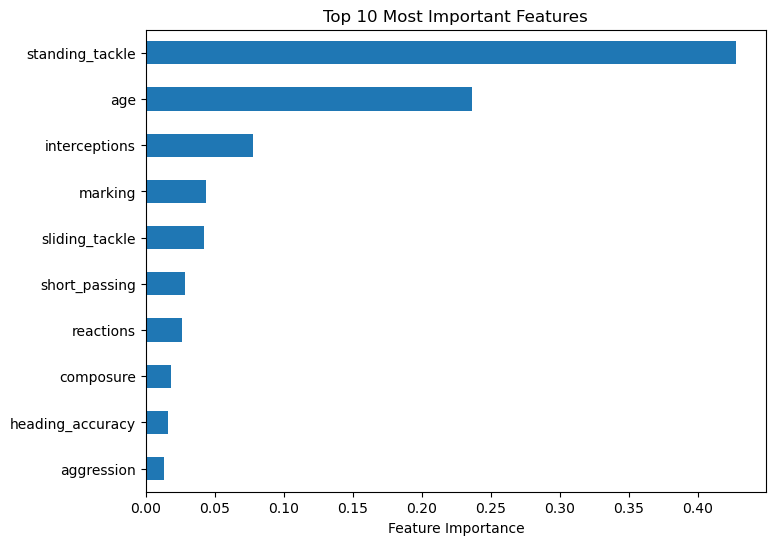

In [48]:
 # create a feature importance ranking
importance = pd.Series(
    rf.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

 # visualize the top 10 important features
plt.figure(figsize=(8,6))
importance.head(10).plot(kind='barh')
plt.xlabel("Feature Importance")
plt.title("Top 10 Most Important Features")
plt.gca().invert_yaxis()
plt.show()

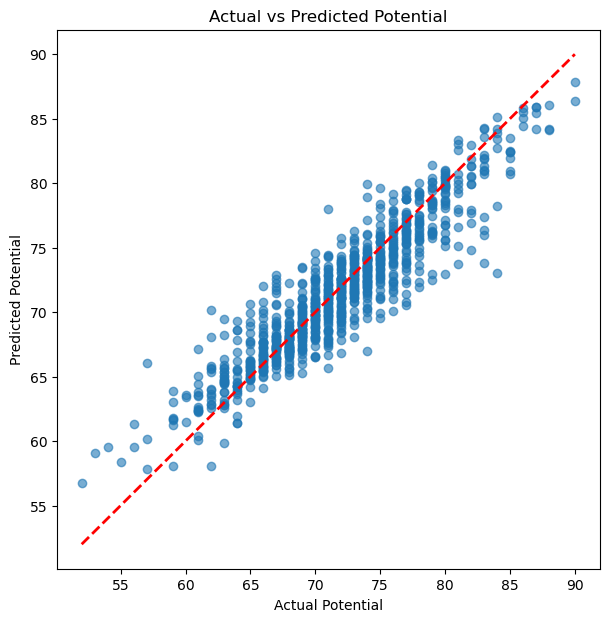

In [49]:
 #Plot Actual vs Predicted scatter
plt.figure(figsize=(7,7))
plt.scatter(y_test, y_hat3, alpha=0.6)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linestyle='--',
    linewidth=2
)

plt.xlabel("Actual Potential")
plt.ylabel("Predicted Potential")
plt.title("Actual vs Predicted Potential")

plt.show()

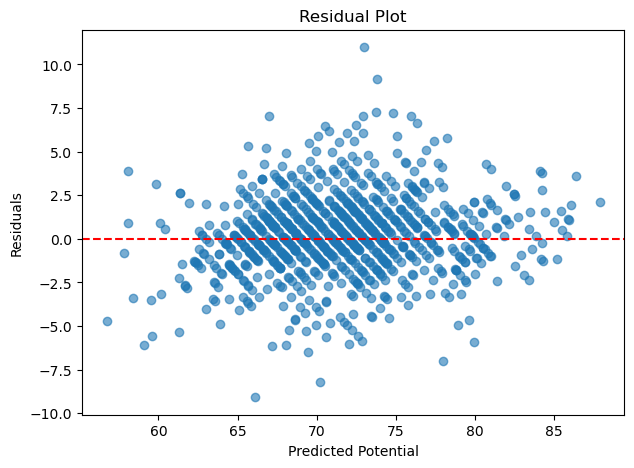

In [50]:
 #PLot residuals scatter
residuals = y_test - y_hat3

plt.figure(figsize=(7,5))
plt.scatter(y_hat3, residuals, alpha=0.6)

plt.axhline(
    y=0,
    color='red',
    linestyle='--'
)

plt.xlabel("Predicted Potential")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.show()